In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Style configuration
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda x: '%.2f' % x)

data_path = os.path.join("..", "data", "processed", "merged_international_debt_analysis.csv")
print("Loading merged dataset...")
df = pd.read_csv(data_path)

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
df.head(3)

Loading merged dataset...
Shape: (1574450, 11)
Columns: ['Country Name', 'Country Code', 'Counterpart-Area Name', 'Counterpart-Area Code', 'Series Name', 'Series Code', 'Year', 'Debt_Value', 'Region', 'Income_Group', 'Topic']


,Country Name,Country Code,Counterpart-Area Name,Counterpart-Area Code,Series Name,Series Code,Year,Debt_Value,Region,Income_Group,Topic
0,Afghanistan,AFG,World,WLD,Average grace period on new external debt comm...,DT.GPA.DPPG,2000,10.25,Middle East & North Africa,Low income,Economic Policy & Debt: External debt: Terms
1,Afghanistan,AFG,World,WLD,Average grace period on new external debt comm...,DT.GPA.OFFT,2000,10.25,Middle East & North Africa,Low income,Economic Policy & Debt: External debt: Terms
2,Afghanistan,AFG,World,WLD,Average grace period on new external debt comm...,DT.GPA.PRVT,2000,0.00,Middle East & North Africa,Low income,Economic Policy & Debt: External debt: Terms


In [2]:
print("Missing values across columns:")
print(df.isnull().sum())

print("\nDebt Value Numerical Summary:")
df[['Debt_Value']].describe()

Missing values across columns:
Country Name             0
Country Code             0
Counterpart-Area Name    0
Counterpart-Area Code    0
Series Name              0
Series Code              0
Year                     0
Debt_Value               0
Region                   0
Income_Group             0
Topic                    0
dtype: int64

Debt Value Numerical Summary:


,Debt_Value
count,1574450.00
mean,8107318816.33
std,192244457595.38
min,-527000000000.00
25%,0.00
50%,6756846.35
75%,242516416.97
max,38200000000000.00


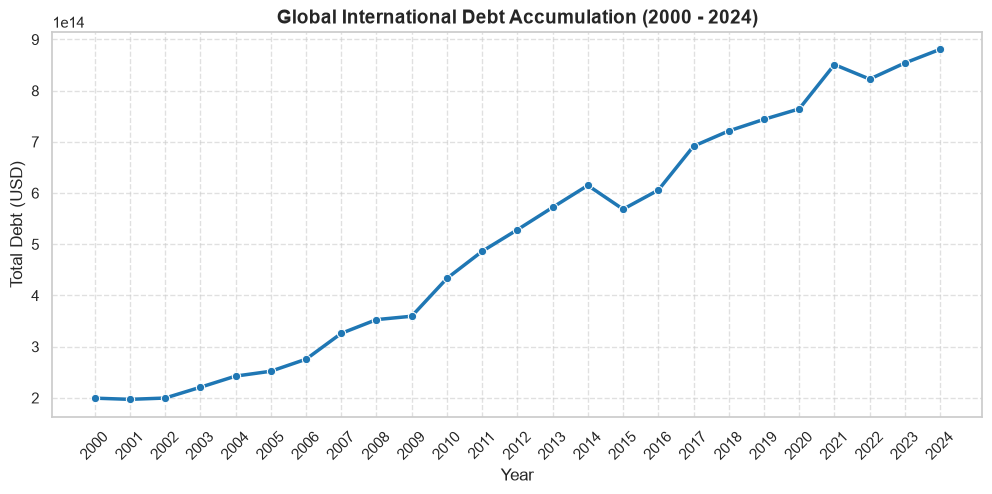

In [ ]:
# Global Debt Trend Over Time (2000–2024)
yearly_debt = df.groupby('Year')['Debt_Value'].sum().reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=yearly_debt, x='Year', y='Debt_Value', marker='o', color='#1f77b4', linewidth=2.5)
plt.title('Global International Debt Accumulation (2000 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Debt (USD)', fontsize=12)
plt.xticks(yearly_debt['Year'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

/var/folders/tw/9cmksmbx35j35qg2c0gpy37w0000gp/T/ipykernel_9874/2291551533.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x='Debt_Value', y='Country Name', palette='viridis')


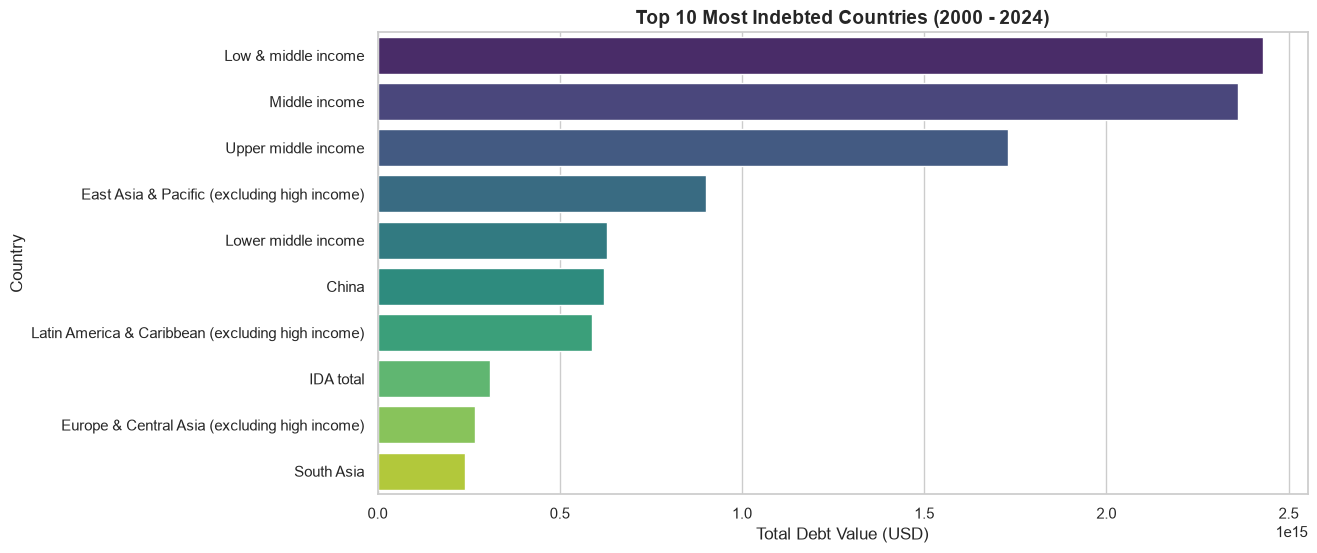

In [ ]:
# Top 10 Most Indebted Countries
top_10 = (
    df.groupby('Country Name')['Debt_Value']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10, x='Debt_Value', y='Country Name', palette='viridis')
plt.title('Top 10 Most Indebted Countries (2000 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Total Debt Value (USD)', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.show()

/var/folders/tw/9cmksmbx35j35qg2c0gpy37w0000gp/T/ipykernel_9874/3628845112.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_debt, x='Debt_Value', y='Region', palette='mako')


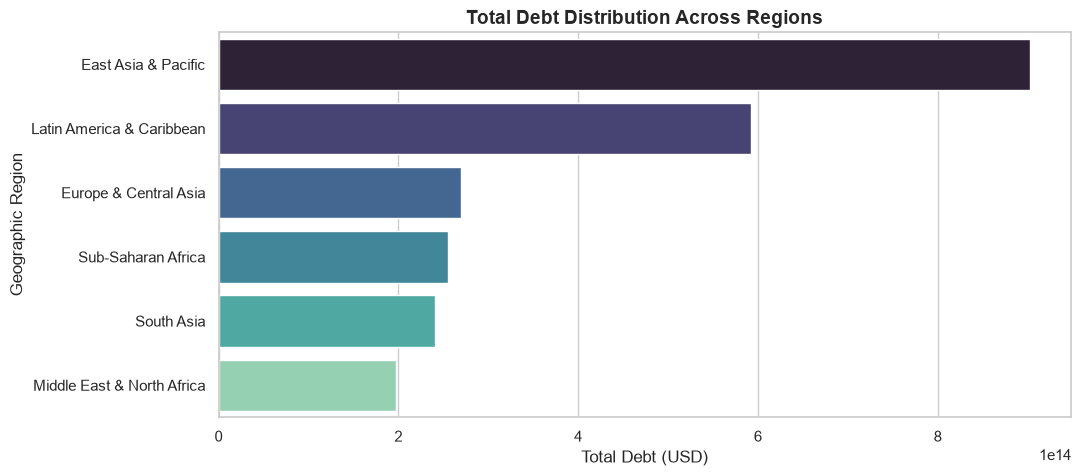

In [ ]:
# Regional Debt Distribution
region_debt = (
    df[df['Region'] != 'Unknown']
    .groupby('Region')['Debt_Value']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(11, 5))
sns.barplot(data=region_debt, x='Debt_Value', y='Region', palette='mako')
plt.title('Total Debt Distribution Across Regions', fontsize=14, fontweight='bold')
plt.xlabel('Total Debt (USD)', fontsize=12)
plt.ylabel('Geographic Region', fontsize=12)
plt.show()

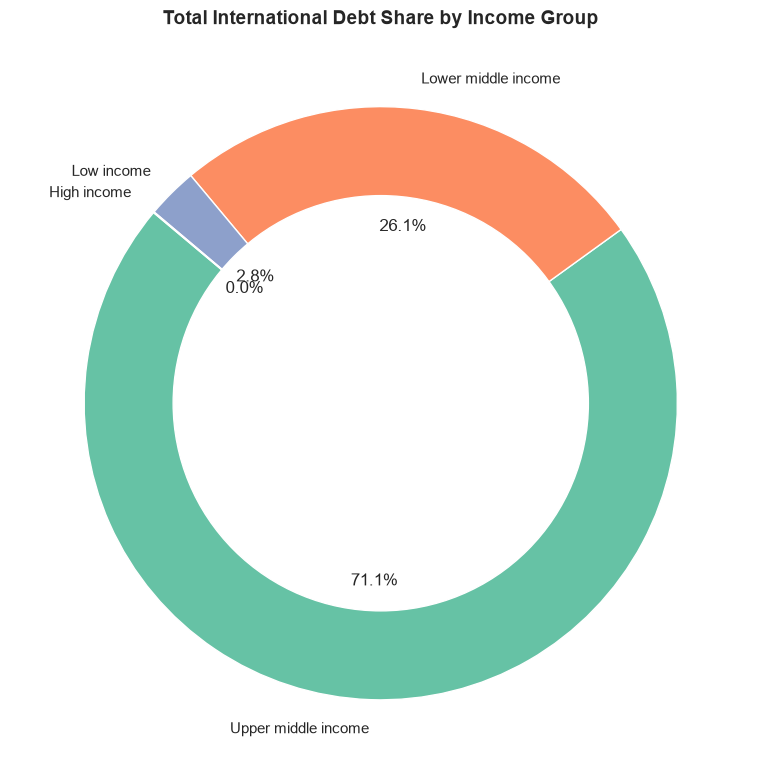

In [11]:
# Debt Breakdown by Income Group (Donut Chart using Matplotlib)
income_debt = (
    df[df['Income_Group'] != 'Unknown']
    .groupby('Income_Group')['Debt_Value']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(8, 8))
plt.pie(
    income_debt['Debt_Value'],
    labels=income_debt['Income_Group'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('Set2')
)

# Convert into a Donut Chart
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

plt.title('Total International Debt Share by Income Group', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

/var/folders/tw/9cmksmbx35j35qg2c0gpy37w0000gp/T/ipykernel_9874/2704893734.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_indicators, x='Debt_Value', y='Series Name', palette='rocket')


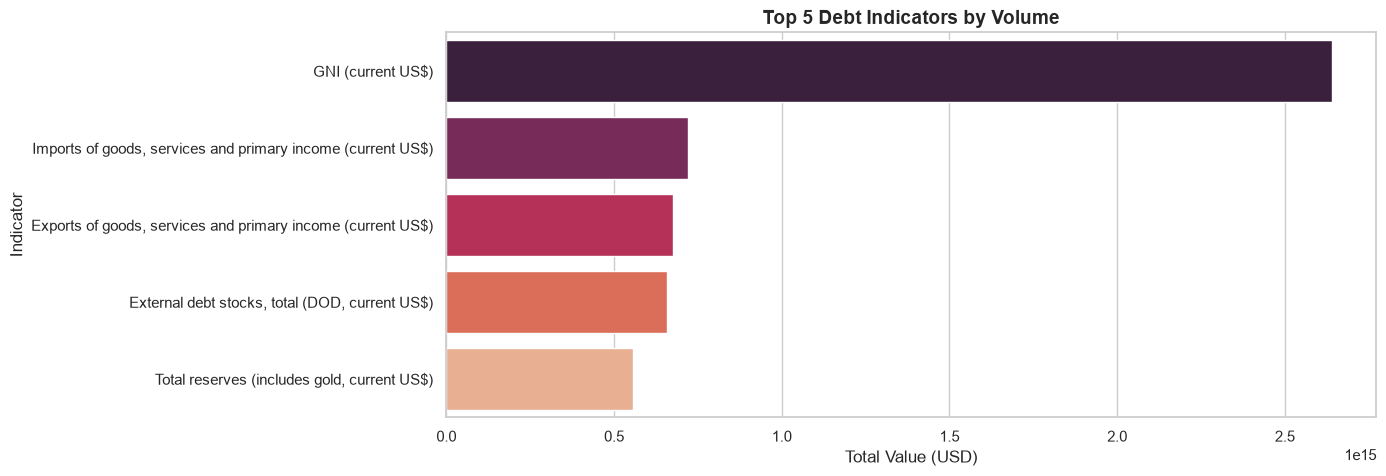

In [12]:
# Top 5 Contributing Indicators
top_indicators = (
    df.groupby('Series Name')['Debt_Value']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

plt.figure(figsize=(12, 5))
sns.barplot(data=top_indicators, x='Debt_Value', y='Series Name', palette='rocket')
plt.title('Top 5 Debt Indicators by Volume', fontsize=14, fontweight='bold')
plt.xlabel('Total Value (USD)', fontsize=12)
plt.ylabel('Indicator', fontsize=12)
plt.show()